# **[실습] RNN - LSTM 주가 데이터 예측**

* https://data.krx.co.kr/contents/MDC/MAIN/main/index.cmd
* https://pypi.org/project/pykrx-openapi/
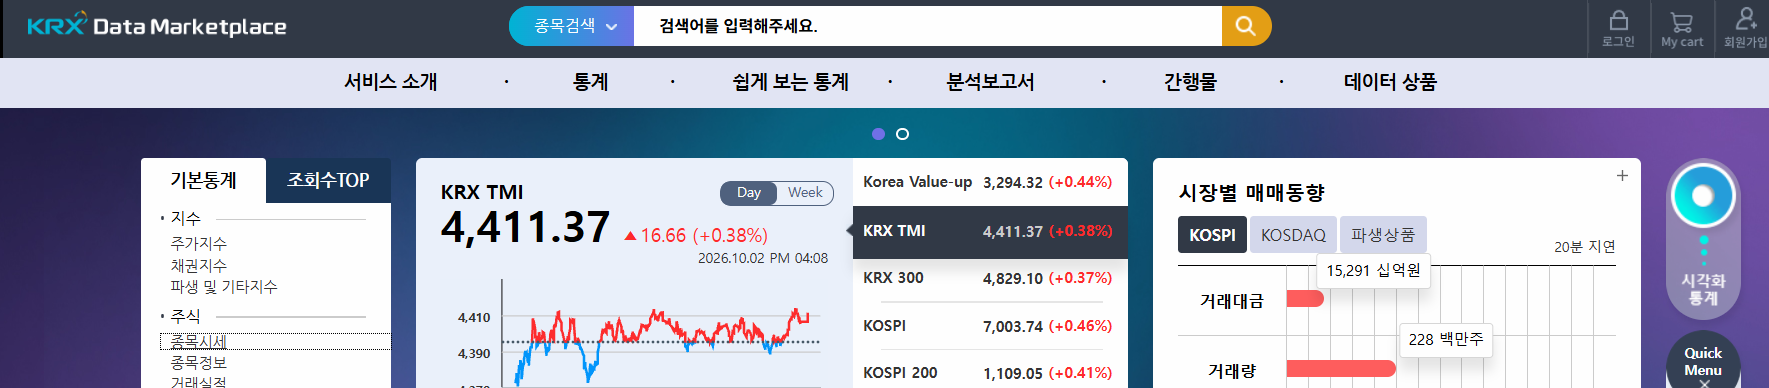

---

* https://financedata.github.io/posts/finance-data-reader-users-guide.html
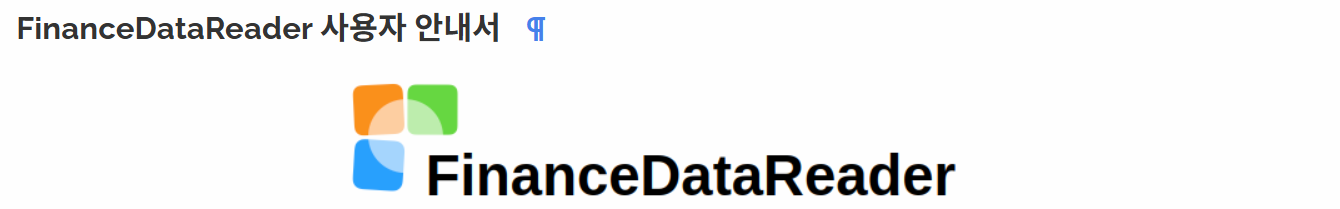

In [1]:
#!pip install finance-datareader

---

In [2]:
import FinanceDataReader as fdr

In [3]:
import os
# TensorFlow 안내 및 경고 로그 끄기 (3 = ERROR/FATAL 로그만 표시)
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
# oneDNN 최적화 관련 안내 문구 숨기기
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
# absl 라이브러리 초기화 전 경고(WARNING: All log messages...) 숨기기
os.environ['ABSL_LOGGING_MIN_LOG_LEVEL'] = '3'

import warnings
warnings.filterwarnings(action='ignore')

from sklearn import set_config
set_config(display="text")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()

import tensorflow as tf
tf.random.set_seed(1234)
np.random.seed(1234)

from sklearn.model_selection import train_test_split   #---- 문제답 분리

from keras.models import Sequential
#from keras.layers import Conv2D, MaxPooling2D  #---- CNN
from tensorflow.keras.layers import SimpleRNN , LSTM, Input, Reshape  #-----RNN
from keras.layers import Dense, Flatten                      #---- FC

#---------------------- 한글 폰트 지정 -----------------------
plt.rcParams["axes.unicode_minus"] = False                   # 마이너스 기호 깨짐 방지

#plt.rcParams["font.family"] = "Malgun Gothic"               #--------------윈도우 인 경우 
import matplotlib.font_manager as fm                         #--------------리눅스인 경우
font_path = "/usr/share/fonts/truetype/nanum/NanumGothic.ttf"
fm.fontManager.addfont(font_path)
font_prop = fm.FontProperties(fname=font_path)
plt.rcParams["font.family"] = font_prop.get_name()

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error

# **Data Load**

In [4]:
df = fdr.DataReader('010950')
df.columns = df.columns.str.lower()
df.head(2)

,open,high,low,close,volume,change
Date,,,,,,
2014-07-14,54000,54500,53600,54200,113951,NaN
2014-07-15,54000,55700,53900,54300,191776,0.001845


In [5]:
min(df.index), max(df.index)

(Timestamp('2014-07-14 00:00:00'), Timestamp('2026-10-06 00:00:00'))

In [6]:
#df = df.loc['2016-01-01 00:00:00':'2026-09-30 23:59:59',  :]
df.info()  

<class 'pandas.DataFrame'>
DatetimeIndex: 3000 entries, 2014-07-14 to 2026-10-06
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   open    3000 non-null   int64  
 1   high    3000 non-null   int64  
 2   low     3000 non-null   int64  
 3   close   3000 non-null   int64  
 4   volume  3000 non-null   int64  
 5   change  2999 non-null   float64
dtypes: float64(1), int64(5)
memory usage: 164.1 KB


# **EDA**

### seaborn

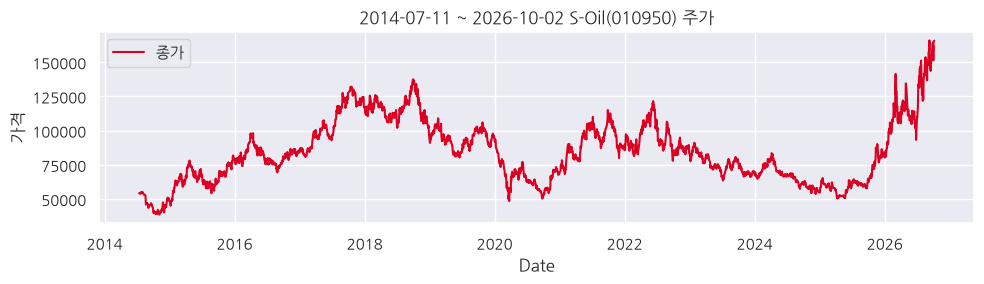

In [7]:
plt.figure(figsize=(10, 3))

# 각 기온 선 그래프 그리기 (이미지 색상 매칭: 최저=블루, 평균=그린, 최고=레드)
# sns.lineplot(data=df, x=df.index, y="open", color="#0055ff",  label="시작가")
# sns.lineplot(data=df, x=df.index, y="high", color="#33cc33", label="고가")
# sns.lineplot(data=df, x=df.index, y="low",  color="#ff0022",  label="저가")
sns.lineplot(data=df, x=df.index, y="close", color="#dd0022",  label="종가")

plt.title("2014-07-11 ~ 2026-10-02 S-Oil(010950) 주가")
plt.ylabel("가격")

plt.legend()
plt.tight_layout()
plt.show()

### plotly

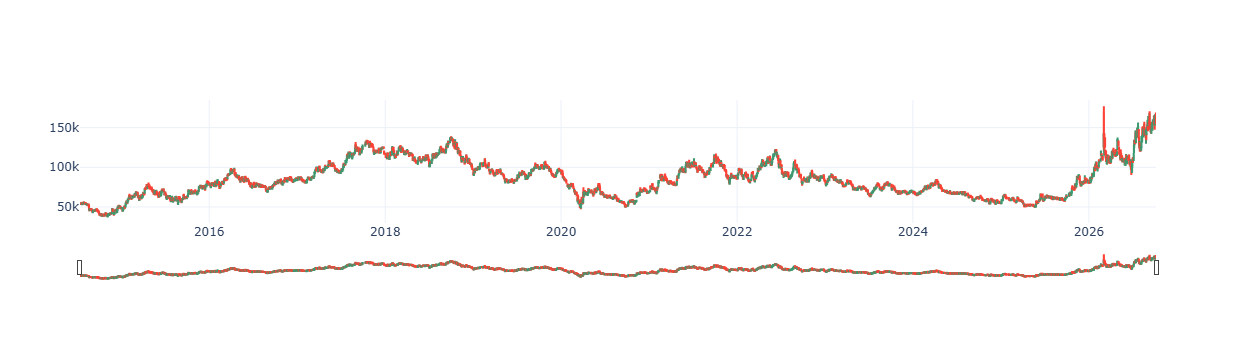

In [8]:
import plotly.graph_objects as go
fig = go.Figure(data=[go.Candlestick(x=df.index,
                open=df['open'],
                high=df['high'],
                low=df['low'],
                close=df['close'])])
fig.show()

### mpl_finance

In [9]:
# pip install --upgrade mplfinance

In [10]:
# import mpl_finance
# import matplotlib.ticker as ticker

# fig = plt.figure(figsize=(12, 4))
# ax = fig.add_subplot(111)
# dfcp = df.iloc[:40]
# date_list = dfcp.index.strftime('%Y-%m-%d')
# # print(date_list)
# ax.xaxis.set_major_formatter(ticker.FixedFormatter(date_list))

# mpl_finance.candlestick2_ohlc(ax, dfcp['open'], dfcp['high'], dfcp['low'], dfcp['close'], width=0.5, colorup='r', colordown='b')
# plt.show()

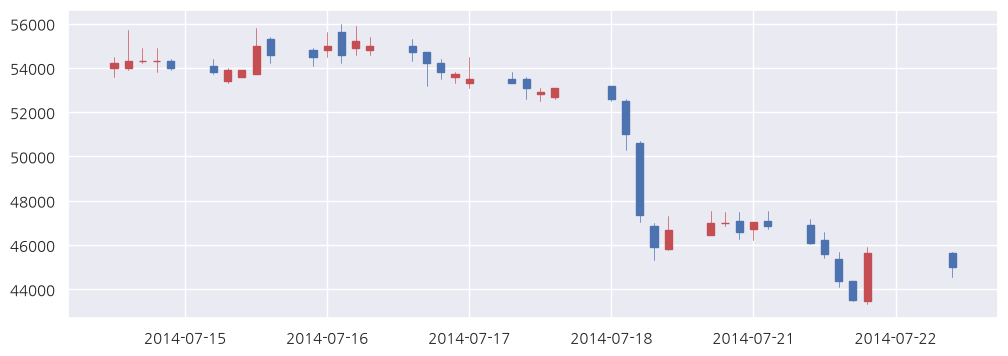

In [11]:
import mplfinance as mpf
import matplotlib.ticker as ticker
from mplfinance.original_flavor import candlestick_ohlc
import matplotlib.dates as mdates

fig = plt.figure(figsize=(12, 4))
ax = fig.add_subplot(111)
dfcp = df.iloc[:40]
date_list = dfcp.index.strftime('%Y-%m-%d')
# print(date_list)
ax.xaxis.set_major_formatter(ticker.FixedFormatter(date_list))

dfcp= dfcp.reset_index()
dfcp['Date'] = dfcp['Date'].apply(lambda x: mdates.date2num(x))

ohlc_data = dfcp[['Date', 'open', 'high', 'low', 'close']].values
candlestick_ohlc(ax, ohlc_data, width=0.5, colorup='r', colordown='b')
#candlestick_ohlc(ax, dfcp['open'], dfcp['high'], dfcp['low'], dfcp['close'], width=0.5, colorup='r', colordown='b')
plt.show()

# **전처리 & 가공**

## 결측채우기

In [12]:
df['change'] = df['change'].bfill()
df.head(2)

,open,high,low,close,volume,change
Date,,,,,,
2014-07-14,54000,54500,53600,54200,113951,0.001845
2014-07-15,54000,55700,53900,54300,191776,0.001845


In [13]:
df.shape

(3000, 6)

## 파생피쳐
* 5(주),  20(월), 60(분기4), 120(분기2), 200(년)

### 이동평균(MA)
* SMA — Simple Moving Average
* EMA — Exponential Moving Average

Object `talib.SMA` not found.


In [1]:
import talib
df["ma5"] = talib.SMA(df["close"], timeperiod=5)
#df['ma5'] = df['close'].rolling(5).mean()

NameError: name 'df' is not defined

In [3]:
import talib

talib.SMA?

Signature: talib.SMA(real, timeperiod=-2147483648)
Docstring:
SMA(ndarray real, int timeperiod=-0x80000000)

SMA(real[, timeperiod=?])

Simple Moving Average (Overlap Studies)

Inputs:
    real: (any ndarray)
Parameters:
    timeperiod: 30
Outputs:
    real
Type:      function

In [15]:
df['ma5'] = df["ma5"].bfill()
df.head(2)

,open,high,low,close,volume,change,ma5
Date,,,,,,,
2014-07-14,54000,54500,53600,54200,113951,0.001845,54220.0
2014-07-15,54000,55700,53900,54300,191776,0.001845,54220.0


### RSI
* RSI — Relative Strength Index

In [16]:
df["RSI"] = talib.RSI(df["close"], timeperiod=5)
df['RSI'] = df["RSI"].bfill()
df.head(2)

,open,high,low,close,volume,change,ma5,RSI
Date,,,,,,,,
2014-07-14,54000,54500,53600,54200,113951,0.001845,54220.0,16.666667
2014-07-15,54000,55700,53900,54300,191776,0.001845,54220.0,16.666667


### BB
* Bollinger Bands — 볼린저 밴드
* upper lower  ma20

In [17]:
upperband, middleband, lowerband = talib.BBANDS(
    df["close"],
    timeperiod=5,
    nbdevup=2.0,  # 상단 표준편차 승수
    nbdevdn=2.0,  # 하단 표준편차 승수
    matype=0,  # 0: SMA (단순이동평균)
)

df["bb_upper"] = upperband
df["bb_lower"] = lowerband

In [18]:
df['bb_upper'] = df["bb_upper"].bfill()
df['bb_lower'] = df["bb_lower"].bfill()
df.head(2)

,open,high,low,close,volume,change,ma5,RSI,bb_upper,bb_lower
Date,,,,,,,,,,
2014-07-14,54000,54500,53600,54200,113951,0.001845,54220.0,16.666667,54453.238076,53986.761924
2014-07-15,54000,55700,53900,54300,191776,0.001845,54220.0,16.666667,54453.238076,53986.761924


### 전일대비 증감률
* change 이미 존재

In [19]:
# df['pct'] = df['close'].pct_change(1)
# df['pct'] = df["pct"].bfill()
# df.head(5)

## 스케일링
* change빼고

In [20]:
df.columns

Index(['open', 'high', 'low', 'close', 'volume', 'change', 'ma5', 'RSI',
       'bb_upper', 'bb_lower'],
      dtype='str')

In [21]:
cols = ['open', 'high', 'low', 'volume', 'ma5', 'RSI','bb_upper', 'bb_lower']

scaler = StandardScaler()
df[cols] = scaler.fit_transform(df[cols])

close_scaler = StandardScaler()
df[['close']] = close_scaler.fit_transform(df[['close']])

df.head(2)

,open,high,low,close,volume,change,ma5,RSI,bb_upper,bb_lower
Date,,,,,,,,,,
2014-07-14,-1.362213,-1.363618,-1.356752,-1.351636,-0.749365,0.001845,-1.356927,-1.652552,-1.407996,-1.289377
2014-07-15,-1.362213,-1.311372,-1.343004,-1.347177,-0.523519,0.001845,-1.356927,-1.652552,-1.407996,-1.289377


## 윈도우 슬라이딩

In [22]:
df.columns

Index(['open', 'high', 'low', 'close', 'volume', 'change', 'ma5', 'RSI',
       'bb_upper', 'bb_lower'],
      dtype='str')

In [23]:
target_loc_idx = df.columns.get_loc('close')
target_loc_idx

3

In [24]:
def MY_WINDOW_SLIDING(data,  window_size=5, feature_dim=1, pred_size=5, target='close') :
    data_size = len(data)                #---★5일치예측  
    loop_cnt = data_size - window_size - pred_size + 1

    #------target만 답안지에 넣기 -----------
    target_loc_idx = df.columns.get_loc(target)
    
    X_list = []
    y_list = []
    for i in range(loop_cnt ) : 
        X_list.append( data[i : i+window_size] )
        y_list.append( data[i+window_size : i+window_size+pred_size , target_loc_idx] )
                                                          #---★5일치예측
        
                                #샘플수(덩어리), window_size, 피쳐개수  
    X = np.array(X_list).reshape(-1, window_size, feature_dim)

                                #샘플수(덩어리), 예측개수, 3D더미
    y = np.array(y_list).reshape(-1, pred_size,1)
    #print(X)
    #print(y)
    return X, y

In [25]:
len(df.columns)

10

In [26]:
X,y = MY_WINDOW_SLIDING(df.values,  window_size=5, feature_dim=10, pred_size=5, target='close')
X.shape, y.shape     

((2991, 5, 10), (2991, 5, 1))

# **train(8:2) / test 분리**

In [27]:
X_train = X[ : -1]
y_train = y[ : -1]

X_test  = X[-1 : ]
y_test  = y[-1 : ]


print(len(X_train) , len(X_test),  len(y_train), len(y_test))
print(X_train.shape , X_test.shape, y_train.shape, y_test.shape)

2990 1 2990 1
(2990, 5, 10) (1, 5, 10) (2990, 5, 1) (1, 5, 1)


In [28]:
X8,X2, y8,y2 = train_test_split(X_train, y_train, test_size=.2, shuffle=False)
print(X8.shape,X2.shape, y8.shape,y2.shape )

(2392, 5, 10) (598, 5, 10) (2392, 5, 1) (598, 5, 1)


# **모델생성, 학습, 평가**

## 모델 생성

In [29]:
model = Sequential([
    LSTM(8,  return_sequences=True, activation='tanh', input_shape=(5,10) ) ,
    LSTM(16, return_sequences=True, activation='tanh') ,
    LSTM(4, activation='tanh') ,
    Dense(5),       #---★5일치1개피쳐
    Reshape((5,1))  #---★5일치예측  
])
model.compile(loss='mse', optimizer='adam', metrics=[tf.keras.metrics.RootMeanSquaredError(name='rmse')])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 5, 8)           │           608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 5, 16)          │         1,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 4)              │           336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │            25 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 5, 1)           │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,569 (10.04 KB)

 Trainable params: 2,569 (10.04 KB)

 Non-trainable params: 0 (0.00 B)

## 학습

In [30]:
fit_res = model.fit(X8, y8, epochs=50, batch_size=10, validation_data=(X2, y2))

Epoch 1/50
240/240 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.5249 - rmse: 0.7245 - val_loss: 0.5295 - val_rmse: 0.7277
Epoch 2/50
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1084 - rmse: 0.3293 - val_loss: 0.2434 - val_rmse: 0.4934
Epoch 3/50
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0497 - rmse: 0.2229 - val_loss: 0.1826 - val_rmse: 0.4273
Epoch 4/50
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0362 - rmse: 0.1902 - val_loss: 0.1554 - val_rmse: 0.3942
Epoch 5/50
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0310 - rmse: 0.1760 - val_loss: 0.1399 - val_rmse: 0.3741
Epoch 6/50
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0283 - rmse: 0.1681 - val_loss: 0.1300 - val_rmse: 0.3605
Epoch 7/50
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0265 - rmse: 0.1628 - val_loss: 0.1227 - val_rmse: 0.3503
Epoch 8/50
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0252 - rmse: 0.1588 - val_loss: 0.1171 - val_rmse: 0.3423
Epoch 9/50
240/240 ━━━━━━━━━━━━━━━━━━━━ 

## 평가 시각화

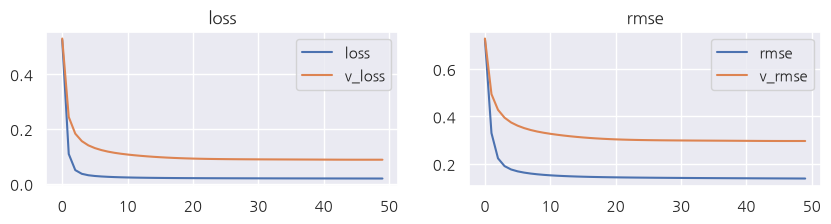

In [31]:
plt.figure(figsize=(10,2))
ax1 = plt.subplot(1,2,1)
ax1.plot(fit_res.history['loss']   ,   label="loss")
ax1.plot(fit_res.history['val_loss'],  label="v_loss")
ax1.legend()
ax1.set_title("loss")

ax2 = plt.subplot(1,2,2)
ax2.plot(fit_res.history['rmse']   ,   label="rmse")
ax2.plot(fit_res.history['val_rmse'],  label="v_rmse")
ax2.legend()
ax2.set_title("rmse")

plt.show()

# **예측**

## 예측 & 답안

In [32]:
pred = model.predict(X_test)
print(pred)
print(y_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step
[[[2.2283502]
  [2.2358735]
  [2.1746695]
  [2.1413982]
  [2.163964 ]]]
[[[3.28641165]
  [3.45587879]
  [2.97869499]
  [3.58520898]
  [3.62088627]]]


## 스케일링 원복 후 점수 보기 

In [33]:
pred    = close_scaler.inverse_transform(pred.reshape(-1,1))     #-------2D : 스케일링 된 예측값 점수 내기전 원복
y_test = close_scaler.inverse_transform(y_test.reshape(-1,1))    #-------2D : 스케일링 된 정답값 점수 내기전 원복

In [34]:
pred , y_test

(array([[134474.84],
        [134643.55],
        [133271.16],
        [132525.11],
        [133031.1 ]], dtype=float32),
 array([[158200.],
        [162000.],
        [151300.],
        [164900.],
        [165700.]]))

In [35]:
rmse = root_mean_squared_error(y_test, pred)
print(f"RMSE : {rmse:.4f}")

RMSE : 27392.2936
